# StreamView Analytics — Integración de fuentes y Análisis Exploratorio (EP2)

**Curso:** ADY1104 – Visualización de Datos · **Equipo:** Bastián Roman · Ignacio Gómez · Vicente Contreras

**Alcance:** integración de las dos fuentes oficiales del caso — *Netflix Movies Detailed up to 2025* y
*Netflix TV Shows Detailed up to 2025* — en un catálogo unificado que alimenta el dashboard de Looker Studio.

Este notebook:
1. Revisa la calidad de **ambas** fuentes (nulos, duplicados, formatos, categorías, fechas, atípicos).
2. Documenta y justifica cada decisión de integración (llave compuesta, géneros armonizados, umbrales).
3. Ejecuta `src/prep.py`, que genera las tablas de `data/processed/` usadas por el dashboard.
4. Realiza el análisis exploratorio con visualizaciones estáticas (exportadas a `images/`).

> Ejecutar de arriba hacia abajo desde la carpeta `notebooks/`. Todas las rutas son relativas.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

sys.path.insert(0, str(Path('..') / 'src'))
import prep  # módulo de integración del proyecto

IMG = Path('..') / 'images'
IMG.mkdir(exist_ok=True)

# Paleta única del proyecto (la misma se usa en Looker Studio)
COL = {'Película': '#2a78d6', 'Serie': '#eb6834'}
GRIS, TINTA, TINTA2 = '#b7b5ae', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GRIS, 'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'legend.frameon': False,
})

def guardar(fig, nombre):
    fig.savefig(IMG / nombre, dpi=200, bbox_inches='tight')

def fmt_miles(x, pos=None):
    return f'{x:,.0f}'.replace(',', '.')

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)

## 1. Calidad de las fuentes

In [2]:
movies, series = prep.cargar()
print('Películas:', movies.shape, '| Series:', series.shape)
print()
print('Columnas solo en películas:', sorted(set(movies.columns) - set(series.columns)))
print('Columnas solo en series:   ', sorted(set(series.columns) - set(movies.columns)))

Películas: (16000, 18) | Series: (16000, 16)

Columnas solo en películas: ['budget', 'revenue']
Columnas solo en series:    []


In [3]:
# 1.1 Nulos por fuente (solo variables con nulos)
nul = pd.DataFrame({
    'Películas %': movies.isna().mean().mul(100).round(1),
    'Series %': series.isna().mean().mul(100).round(1),
})
print(nul[(nul.fillna(0) > 0).any(axis=1)].sort_values('Series %', ascending=False))

             Películas %  Series %
director             0.8      68.5
description          0.8      20.0
country              2.9      11.2
cast                 1.3       7.2
genres               0.7       6.1
duration           100.0       0.0


In [4]:
# 1.2 Duplicados y llaves
print('show_id duplicados en películas:', movies['show_id'].duplicated().sum())
print('show_id duplicados en series:   ', series['show_id'].duplicated().sum())
dup = series[series['show_id'].duplicated(keep=False)].sort_values('show_id')
print(dup[['show_id', 'title', 'release_year', 'vote_count']].head(6).to_string(index=False))
print()
comunes = set(movies['show_id']) & set(series['show_id'])
print(f'show_id presentes en AMBAS fuentes: {len(comunes)} -> show_id no es llave única del catálogo integrado')
ej = sorted(comunes)[0]
print(pd.concat([movies.loc[movies.show_id == ej, ['show_id', 'type', 'title']],
                 series.loc[series.show_id == ej, ['show_id', 'type', 'title']]]).to_string(index=False))

show_id duplicados en películas: 0
show_id duplicados en series:    9
 show_id                                    title  release_year  vote_count
  252630 Joe Lycett’s United States of Birmingham          2025           0
  252630 Joe Lycett’s United States of Birmingham          2025           0
  278867                                 Ensemble          2025           1
  278867                                 Ensemble          2025           1
  279457                           Ghassan & Mina          2025           0
  279457                           Ghassan & Mina          2025           0

show_id presentes en AMBAS fuentes: 397 -> show_id no es llave única del catálogo integrado
 show_id    type                title
   18823   Movie  Clash of the Titans
   18823 TV Show Growing Through Life


In [5]:
# 1.3 Variables que no aportan información
for nombre, df in [('Películas', movies), ('Series', series)]:
    print(f"{nombre}: rating == vote_average en {(df['rating'] == df['vote_average']).mean():.0%} de las filas")
print('Películas: duration vacía en', f"{movies['duration'].isna().mean():.0%}")
print('Series: valores de duration ->', series['duration'].value_counts().to_dict())

Películas: rating == vote_average en 100% de las filas
Series: rating == vote_average en 100% de las filas
Películas: duration vacía en 100%
Series: valores de duration -> {'1 Seasons': 16000}


In [6]:
# 1.4 Fechas: ¿date_added aporta una dimensión temporal propia?
for nombre, df in [('Películas', movies), ('Series', series)]:
    anio_inc = pd.to_datetime(df['date_added']).dt.year
    print(f"{nombre}: año de incorporación == año de estreno en {(anio_inc == df['release_year']).mean():.0%};",
          f"títulos por año: min {df['release_year'].value_counts().min()} / max {df['release_year'].value_counts().max()}")

Películas: año de incorporación == año de estreno en 100%; títulos por año: min 1000 / max 1000
Series: año de incorporación == año de estreno en 100%; títulos por año: min 1000 / max 1000


In [7]:
# 1.5 Votos y valoración: vote_average = 0 cuando nadie ha votado
for nombre, df in [('Películas', movies), ('Series', series)]:
    sin_votos = (df['vote_count'] == 0).mean()
    pocos = (df['vote_count'] < prep.MIN_VOTOS).mean()
    print(f"{nombre}: sin votos {sin_votos:.0%} | menos de {prep.MIN_VOTOS} votos {pocos:.0%} |",
          f"mediana de votos {df['vote_count'].median():.0f} |",
          f"valoración promedio todas {df['vote_average'].mean():.2f} vs confiables {df.loc[df.vote_count >= prep.MIN_VOTOS, 'vote_average'].mean():.2f}")

Películas: sin votos 6% | menos de 10 votos 11% | mediana de votos 138 | valoración promedio todas 5.96 vs confiables 6.35
Series: sin votos 23% | menos de 10 votos 62% | mediana de votos 4 | valoración promedio todas 5.42 vs confiables 7.29


In [8]:
# 1.6 Escalas de popularidad y taxonomías de géneros distintas entre fuentes
print(pd.DataFrame({'Películas': movies['popularity'].describe(percentiles=[.5, .99]),
                    'Series': series['popularity'].describe(percentiles=[.5, .99])}).round(1).T)
print()
gm = set(movies['genres'].dropna().str.split(', ').explode())
gs = set(series['genres'].dropna().str.split(', ').explode())
print('Géneros solo en películas:', sorted(gm - gs))
print('Géneros solo en series:   ', sorted(gs - gm))

             count  mean    std  min   50%    99%     max
Películas  16000.0  20.4   68.6  3.9  10.9  144.5  3876.0
Series     16000.0  64.9  139.4  2.3  36.2  467.7  6421.9

Géneros solo en películas: ['Action', 'Adventure', 'Fantasy', 'History', 'Horror', 'Music', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War']
Géneros solo en series:    ['Action & Adventure', 'Kids', 'News', 'Reality', 'Sci-Fi & Fantasy', 'Soap', 'Talk', 'Unknown', 'War & Politics']


In [9]:
# 1.7 Coherencia presupuesto / ingresos (solo películas)
b, r = movies['budget'], movies['revenue']
print(f'budget = 0: {(b == 0).mean():.1%} | revenue = 0: {(r == 0).mean():.1%}')
fin = movies[(b > 0) & (r > 0)]
print(f'Con ambos datos: {len(fin)} ({len(fin)/len(movies):.1%})')
print(f'Presupuestos < US$1.000 (probable error de carga): {(fin.budget < 1_000).sum()}')
print(fin.nsmallest(5, 'budget')[['title', 'budget', 'revenue']].to_string(index=False))

budget = 0: 69.7% | revenue = 0: 64.7%
Con ambos datos: 3540 (22.1%)
Presupuestos < US$1.000 (probable error de carga): 10
                                             title  budget  revenue
                                    The Quiet Girl       1        6
                                           Red Dog       5       13
The Beatles: Eight Days a Week - The Touring Years       5 12283800
                       No Dogs or Italians Allowed       5  1395922
                                    William & Kate      20       15


### Resumen de calidad y decisiones de integración

| # | Hallazgo | Decisión | Justificación |
|---|---|---|---|
| 1 | `show_id` se repite entre fuentes (397 ids) | Llave compuesta `content_id` = `M-<id>` / `S-<id>` | Sin ella, un join o un conteo distinto mezclaría películas con series. |
| 2 | 9 `show_id` duplicados en series (mismo título) | Se conserva la fila con más votos | Regla de Negocio #1: cada registro es un único contenido. |
| 3 | Taxonomías de géneros distintas (`Action` vs `Action & Adventure`, `Science Fiction` vs `Sci-Fi & Fantasy`) | Mapa de **géneros armonizados** en español (22 categorías) | Permite comparar ambos tipos con la misma lista (Regla #2). Los géneros exclusivos de un tipo se mantienen y se declaran. |
| 4 | Escalas de popularidad distintas (mediana 10,9 películas vs 36,2 series) | Se agrega `popularidad_percentil` dentro de cada tipo | El índice TMDB de series y películas no es comparable en valor absoluto. |
| 5 | `vote_average` = 0 cuando no hay votos; 62% de las series tiene menos de 10 votos | `valoracion_valida` solo con ≥ 10 votos | Evita que ceros sin votos bajen el promedio (5,96 → 6,35 en películas). |
| 6 | `rating` = `vote_average` en el 100% de ambas fuentes | Se excluye como clasificación etaria | No contiene TV-MA, PG-13, etc. como dice el diccionario; los KPIs de clasificación no son calculables. |
| 7 | `duration` vacía (películas) y constante "1 Seasons" (series) | Se excluye | No aporta variación. |
| 8 | `date_added` coincide con el año de estreno y hay 1.000 títulos por año en ambas fuentes | No se afirman tendencias de *volumen*; sí de popularidad y valoración por año | El extracto está muestreado de forma uniforme por año. |
| 9 | `budget`/`revenue` en 0 (69,7% / 64,7%) y presupuestos de US$1–400 | 0 → nulo; ROI solo con presupuesto ≥ US$1 M | Reglas #3, #6 y #9. Evita ROI artificiales de 500x. |
| 10 | `genres` y `country` multivaluados | Tablas puente `catalogo_generos` y `catalogo_paises` | Looker Studio no separa listas; cada género/país se cuenta individualmente. |

In [10]:
# 2. Ejecutar la integración (genera data/processed/*.csv)
prep.main()
cat = pd.read_csv(prep.OUT / 'catalogo_unificado.csv')
gen = pd.read_csv(prep.OUT / 'catalogo_generos.csv')
pai = pd.read_csv(prep.OUT / 'catalogo_paises.csv')
assert cat['content_id'].is_unique
print(cat['tipo'].value_counts().to_string())
print()
print(cat.head(3).T.head(22))

catalogo_unificado: 31,991 filas | generos: 64,765 | paises: 37,628
tipo
Película    16000
Serie       15991

                                                                       0                                              1  \
content_id                                                       M-10192                                        M-27205   
tipo                                                            Película                                       Película   
titulo                                               Shrek Forever After                                      Inception   
anio_estreno                                                        2010                                           2010   
fecha_incorporacion                                           2010-05-16                                     2010-07-15   
periodo                                                        2010-2014                                      2010-2014   
genero_principal             

In [11]:
# 2.1 KPIs de referencia (valores de control para verificar el dashboard)
kpis = pd.read_csv(prep.OUT / 'kpis_referencia.csv')
print(kpis[['kpi', 'valor']].to_string(index=False))

                                                kpi        valor
                                Total de contenidos 3.199100e+04
                                 Total de películas 1.600000e+04
                                    Total de series 1.599100e+04
                               Países representados 1.470000e+02
                                Idiomas disponibles 8.300000e+01
                              Géneros (armonizados) 2.200000e+01
                    Popularidad mediana - películas 1.091000e+01
                       Popularidad mediana - series 3.620000e+01
                         % con valoración confiable 6.355000e+01
                      Valoración promedio confiable 6.630000e+00
          Valoración promedio confiable - películas 6.350000e+00
             Valoración promedio confiable - series 7.290000e+00
                                      Joyas ocultas 5.256000e+03
                                          Estrellas 2.717000e+03
                    Pelíc

## 3. Análisis exploratorio

Cada gráfico se guarda en `images/` en alta resolución para el informe y la presentación.

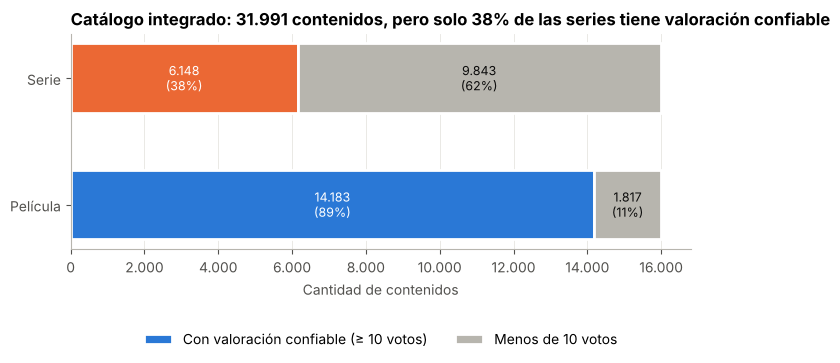

In [12]:
# G1. Composición del catálogo y confiabilidad de la valoración
t = pd.crosstab(cat['tipo'], cat['valoracion_confiable']).reindex(columns=['Sí', 'No'])
fig, ax = plt.subplots(figsize=(8, 2.8))
izq = np.zeros(len(t))
for col, color, etiqueta in [('Sí', None, 'Con valoración confiable (≥ 10 votos)'), ('No', GRIS, 'Menos de 10 votos')]:
    colores = [COL[i] if color is None else color for i in t.index]
    ax.barh(t.index, t[col], left=izq, color=colores, edgecolor='white', linewidth=2, height=0.55, label=etiqueta)
    for i, (v, l) in enumerate(zip(t[col], izq)):
        ax.text(l + v / 2, i, f'{v:,.0f}'.replace(',', '.') + f'\n({v / t.sum(axis=1).iloc[i]:.0%})',
                ha='center', va='center', fontsize=9, color='white' if color is None else TINTA)
    izq += t[col].values
ax.set_title('Catálogo integrado: 31.991 contenidos, pero solo 38% de las series tiene valoración confiable')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(fmt_miles))
ax.set_xlabel('Cantidad de contenidos')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=2)
guardar(fig, 'ep2_01_composicion_catalogo.png'); plt.show()

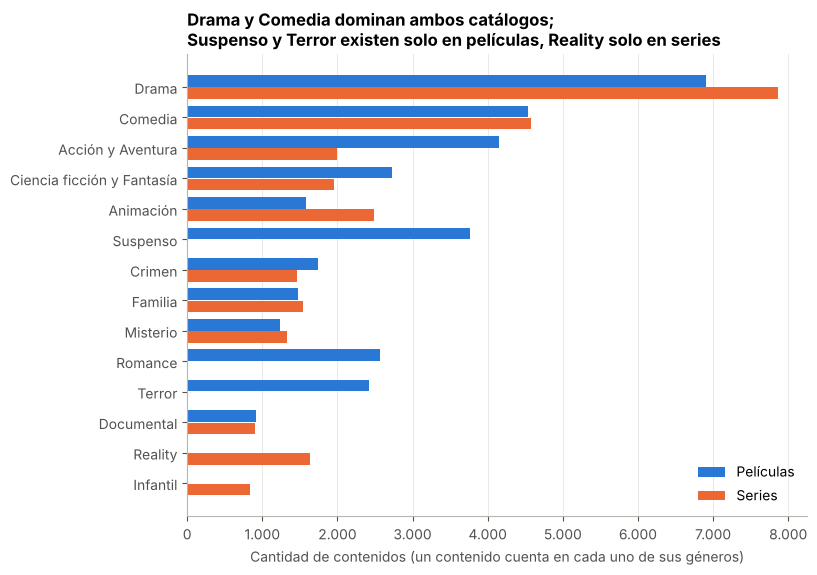

In [13]:
# G2. Géneros armonizados: presencia por tipo (cada género contado individualmente)
g = gen.groupby(['genero', 'tipo'])['content_id'].nunique().unstack(fill_value=0)
g['total'] = g.sum(axis=1)
g = g.sort_values('total').tail(14)
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(g))
ax.barh(y + 0.2, g['Película'], height=0.38, color=COL['Película'], label='Películas')
ax.barh(y - 0.2, g['Serie'], height=0.38, color=COL['Serie'], label='Series')
ax.set_yticks(y, g.index)
ax.set_title('Drama y Comedia dominan ambos catálogos;\nSuspenso y Terror existen solo en películas, Reality solo en series')
ax.set_xlabel('Cantidad de contenidos (un contenido cuenta en cada uno de sus géneros)')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(fmt_miles))
ax.grid(axis='y', visible=False); ax.legend(loc='lower right')
guardar(fig, 'ep2_02_generos_por_tipo.png'); plt.show()

tipo                        Película  Serie
genero                                     
Acción y Aventura               66.4   54.4
Ciencia ficción y Fantasía      65.7   52.9
Animación                       64.5   49.8
Familia                         60.8   62.8
Suspenso                        58.1    NaN
Misterio                        56.0   46.8
Crimen                          55.6   50.7
Bélico y Política               54.4   47.3
Terror                          53.1    NaN
Historia                        52.7    NaN
Western                         52.2    NaN
Romance                         48.3    NaN
Comedia                         47.7   50.6
Drama                           47.7   51.1
Música                          42.2    NaN
Documental                      30.1   38.6
Película para TV                28.2    NaN
Infantil                         NaN   56.9
Noticias                         NaN   69.3
Reality                          NaN   56.6
Talk show                       

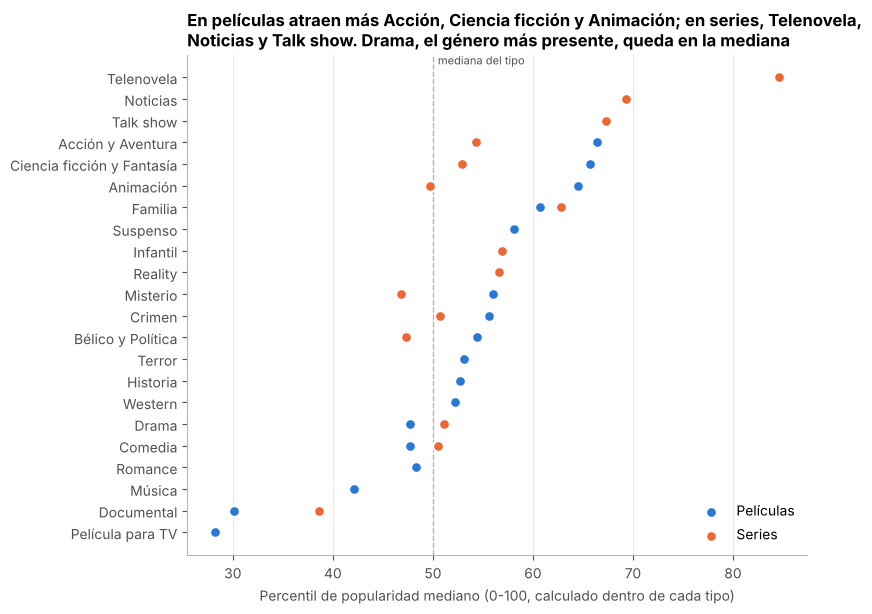

In [14]:
# G3. Presencia vs atractivo por género (popularidad relativa dentro de cada tipo)
r = (gen.groupby(['genero', 'tipo'])
        .agg(n=('content_id', 'nunique'), pop=('popularidad_percentil', 'median'))
        .reset_index())
r = r[r['n'] >= 100]
orden = r.groupby('genero')['pop'].max().sort_values().index
fig, ax = plt.subplots(figsize=(8, 6.5))
for tipo, d in r.groupby('tipo'):
    d = d.set_index('genero').reindex(orden)
    ax.scatter(d['pop'], range(len(orden)), s=60, color=COL[tipo], label=tipo + 's', zorder=3,
               edgecolor='white', linewidth=1.5)
ax.axvline(50, color=GRIS, linestyle='--', linewidth=1)
ax.text(50.5, len(orden) - 0.4, 'mediana del tipo', color=TINTA2, fontsize=8)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlabel('Percentil de popularidad mediano (0-100, calculado dentro de cada tipo)')
ax.set_title('En películas atraen más Acción, Ciencia ficción y Animación; en series, Telenovela,\nNoticias y Talk show. Drama, el género más presente, queda en la mediana')
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
guardar(fig, 'ep2_03_atractivo_por_genero.png'); plt.show()
print(r.pivot(index='genero', columns='tipo', values='pop').round(1).sort_values('Película', ascending=False).to_string())

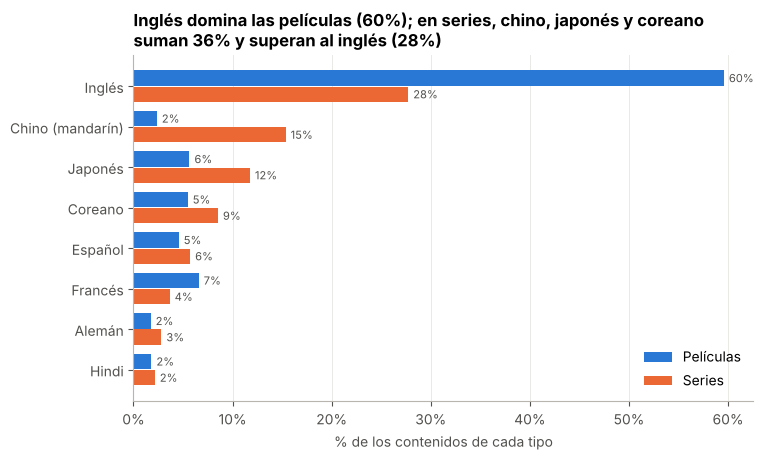

In [15]:
# G4. Idiomas: el catálogo de series está mucho más concentrado en Asia
top = cat['idioma'].value_counts().head(8).index
p = (pd.crosstab(cat['idioma'], cat['tipo'], normalize='columns') * 100).loc[top][::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(p))
ax.barh(y + 0.2, p['Película'], height=0.38, color=COL['Película'], label='Películas')
ax.barh(y - 0.2, p['Serie'], height=0.38, color=COL['Serie'], label='Series')
for i, (a, b) in enumerate(zip(p['Película'], p['Serie'])):
    ax.text(a + 0.5, i + 0.2, f'{a:.0f}%', va='center', fontsize=8, color=TINTA2)
    ax.text(b + 0.5, i - 0.2, f'{b:.0f}%', va='center', fontsize=8, color=TINTA2)
ax.set_yticks(y, p.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel('% de los contenidos de cada tipo')
ax.set_title('Inglés domina las películas (60%); en series, chino, japonés y coreano\nsuman 36% y superan al inglés (28%)')
ax.grid(axis='y', visible=False); ax.legend(loc='lower right')
guardar(fig, 'ep2_04_idiomas_por_tipo.png'); plt.show()

Contenidos con EE.UU. entre sus países: 34.2%


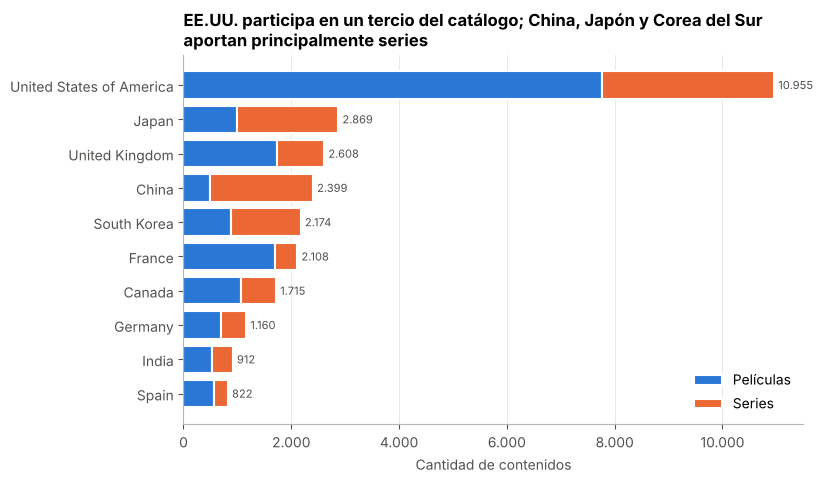

In [16]:
# G5. Países productores (cada país de una coproducción cuenta)
pp = pai.groupby(['pais', 'tipo'])['content_id'].nunique().unstack(fill_value=0)
pp['total'] = pp.sum(axis=1)
pp = pp.sort_values('total').tail(10)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(pp.index, pp['Película'], color=COL['Película'], label='Películas', edgecolor='white', linewidth=1.5)
ax.barh(pp.index, pp['Serie'], left=pp['Película'], color=COL['Serie'], label='Series', edgecolor='white', linewidth=1.5)
for i, v in enumerate(pp['total']):
    ax.text(v + 80, i, fmt_miles(v), va='center', fontsize=8, color=TINTA2)
ax.set_title('EE.UU. participa en un tercio del catálogo; China, Japón y Corea del Sur\naportan principalmente series')
ax.set_xlabel('Cantidad de contenidos')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(fmt_miles))
ax.grid(axis='y', visible=False); ax.legend(loc='lower right')
guardar(fig, 'ep2_05_paises.png'); plt.show()
print(f"Contenidos con EE.UU. entre sus países: {pai.loc[pai.pais=='United States of America','content_id'].nunique() / len(cat):.1%}")

                  val       confiable      
tipo         Película Serie  Película Serie
anio_estreno                               
2010              6.1   7.2      97.1  30.2
2011              6.2   7.2      98.2  30.2
2012              6.1   7.2      97.8  31.6
2013              6.2   7.2      97.3  33.8
2014              6.2   7.1      97.6  36.9
2015              6.2   7.2      96.8  37.8
2016              6.3   7.1      94.1  39.7
2017              6.4   7.2      94.7  41.6
2018              6.4   7.3      93.3  42.9
2019              6.5   7.4      93.8  45.5
2020              6.5   7.4      88.7  48.4
2021              6.5   7.4      92.3  48.9
2022              6.5   7.3      94.5  44.4
2023              6.5   7.4      91.2  46.6
2024              6.5   7.4      82.3  49.7
2025              6.5   7.5       8.6   6.7


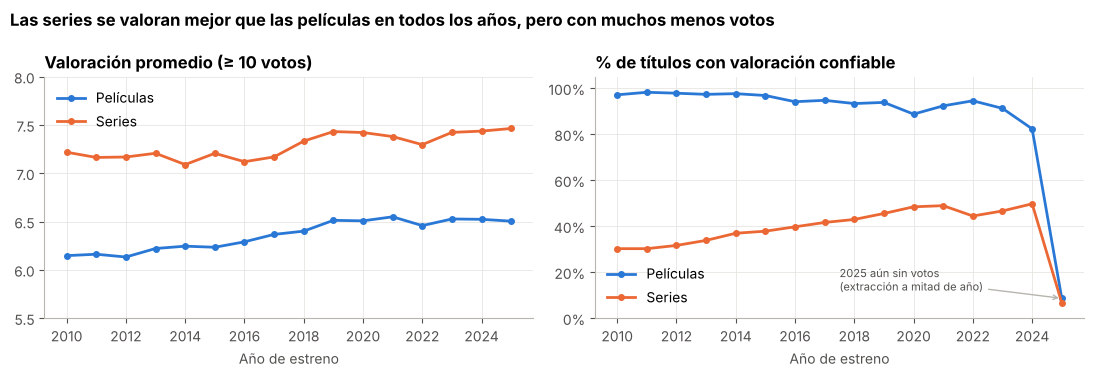

In [17]:
# G6. Evolución temporal (el volumen es constante: 1.000 títulos por año y tipo)
anual = (cat.groupby(['anio_estreno', 'tipo'])
            .agg(pop=('popularidad', 'median'), val=('valoracion_valida', 'mean'),
                 confiable=('valoracion_confiable', lambda s: (s == 'Sí').mean() * 100))
            .reset_index())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for tipo, d in anual.groupby('tipo'):
    axs[0].plot(d['anio_estreno'], d['val'], color=COL[tipo], linewidth=2, marker='o', markersize=4, label=tipo + 's')
    axs[1].plot(d['anio_estreno'], d['confiable'], color=COL[tipo], linewidth=2, marker='o', markersize=4, label=tipo + 's')
axs[0].set_title('Valoración promedio (≥ 10 votos)'); axs[0].set_ylim(5.5, 8)
axs[1].set_title('% de títulos con valoración confiable')
axs[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axs[1].set_ylim(0, 105)
for a in axs:
    a.set_xlabel('Año de estreno'); a.legend()
axs[1].annotate('2025 aún sin votos\n(extracción a mitad de año)', xy=(2025, anual.query('anio_estreno==2025 and tipo=="Película"')['confiable'].iloc[0]),
                xytext=(2017.5, 12), fontsize=8, color=TINTA2, arrowprops=dict(arrowstyle='->', color=GRIS))
fig.suptitle('Las series se valoran mejor que las películas en todos los años, pero con muchos menos votos', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar(fig, 'ep2_06_evolucion_temporal.png'); plt.show()
print(anual.pivot(index='anio_estreno', columns='tipo', values=['val', 'confiable']).round(1).to_string())

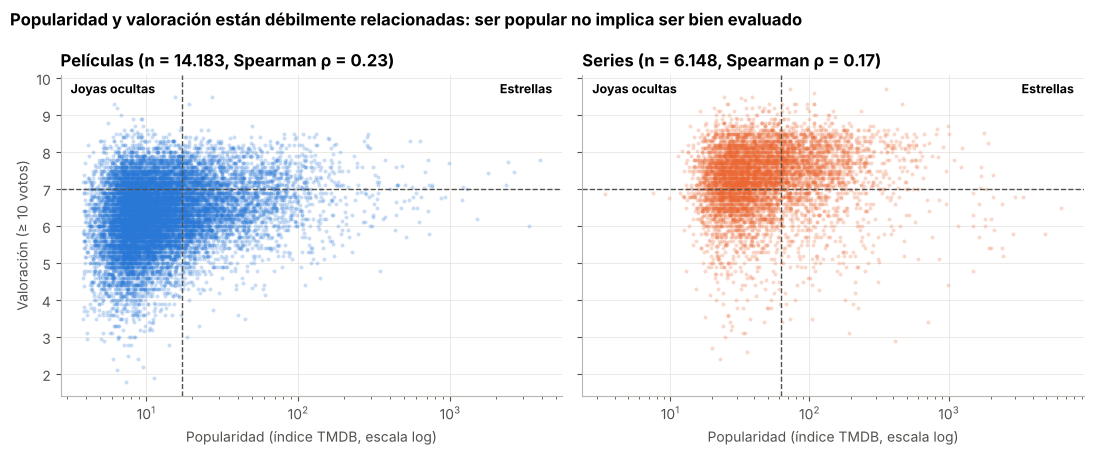

In [18]:
# G7. Popularidad vs valoración (cuadrantes de atractivo)
d = cat.dropna(subset=['valoracion_valida'])
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for a, (tipo, x) in zip(axs, d.groupby('tipo')):
    corte = cat.loc[cat['tipo'] == tipo, 'popularidad'].quantile(prep.PERCENTIL_ALTO / 100)  # mismo corte que el segmento
    a.scatter(x['popularidad'], x['valoracion_valida'], s=8, alpha=0.25, color=COL[tipo], linewidths=0)
    a.set_xscale('log')
    a.axvline(corte, color=TINTA2, linestyle='--', linewidth=1)
    a.axhline(prep.VALORACION_ALTA, color=TINTA2, linestyle='--', linewidth=1)
    a.text(0.98, 0.98, 'Estrellas', transform=a.transAxes, ha='right', va='top', fontsize=9, fontweight='bold')
    a.text(0.02, 0.98, 'Joyas ocultas', transform=a.transAxes, ha='left', va='top', fontsize=9, fontweight='bold')
    rho = x[['popularidad', 'valoracion_valida']].corr(method='spearman').iloc[0, 1]
    a.set_title(f'{tipo}s (n = {len(x):,}'.replace(',', '.') + f', Spearman ρ = {rho:.2f})')
    a.set_xlabel('Popularidad (índice TMDB, escala log)')
axs[0].set_ylabel('Valoración (≥ 10 votos)')
fig.suptitle('Popularidad y valoración están débilmente relacionadas: ser popular no implica ser bien evaluado',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar(fig, 'ep2_07_popularidad_vs_valoracion.png'); plt.show()

tipo                       Película  Serie    All
segmento                                         
Estrella                       1297   1420   2717
Joya oculta                    2361   2895   5256
Popular, valoración media      2385    432   2817
Estándar                       8140   1401   9541
Sin valoración suficiente      1817   9843  11660
All                           16000  15991  31991


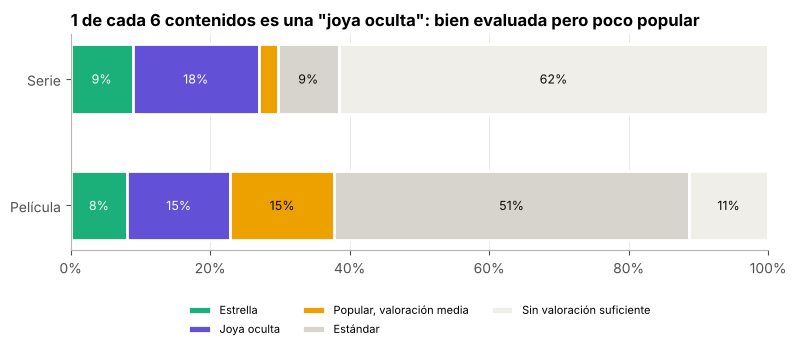

In [19]:
# G8. Segmentos de atractivo por tipo
orden_seg = ['Estrella', 'Joya oculta', 'Popular, valoración media', 'Estándar', 'Sin valoración suficiente']
col_seg = {'Estrella': '#1baf7a', 'Joya oculta': '#6250d6', 'Popular, valoración media': '#eda100',
           'Estándar': '#d6d4cd', 'Sin valoración suficiente': '#efeee9'}
s = (pd.crosstab(cat['tipo'], cat['segmento'], normalize='index') * 100)[orden_seg]
fig, ax = plt.subplots(figsize=(9, 2.8))
izq = np.zeros(len(s))
for seg in orden_seg:
    ax.barh(s.index, s[seg], left=izq, color=col_seg[seg], edgecolor='white', linewidth=2, height=0.55, label=seg)
    for i, v in enumerate(s[seg]):
        if v >= 6:
            ax.text(izq[i] + v / 2, i, f'{v:.0f}%', ha='center', va='center', fontsize=9,
                    color='white' if seg in ('Estrella', 'Joya oculta') else TINTA)
    izq += s[seg].values
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_xlim(0, 100)
ax.grid(axis='y', visible=False)
ax.set_title('1 de cada 6 contenidos es una "joya oculta": bien evaluada pero poco popular')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)
guardar(fig, 'ep2_08_segmentos.png'); plt.show()
print(pd.crosstab(cat['segmento'], cat['tipo'], margins=True).loc[orden_seg + ['All']].to_string())

Películas con datos financieros: 3540 de 16.000 (22.1%) — alcance parcial (Regla #9)


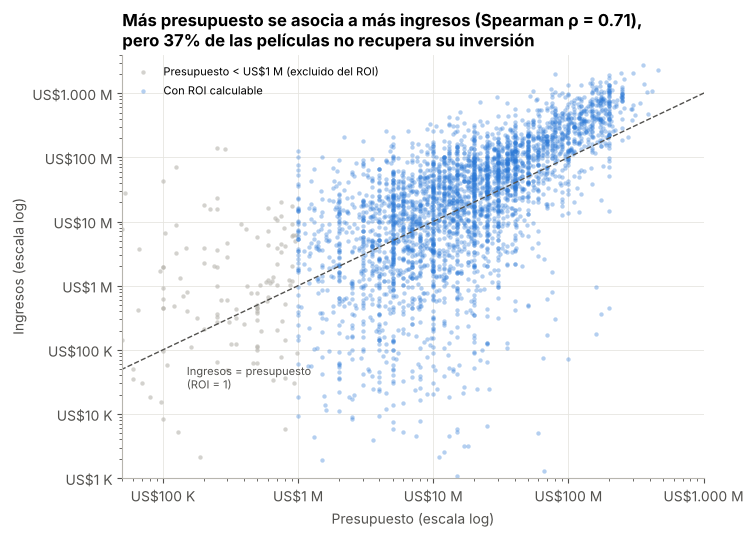

In [20]:
# G9. Presupuesto vs ingresos (solo películas con datos válidos)
f = cat[cat['datos_financieros'] == 'Sí']
fig, ax = plt.subplots(figsize=(7.5, 5.5))
roi_col = f['roi'].notna()
ax.scatter(f.loc[~roi_col, 'presupuesto_usd'], f.loc[~roi_col, 'ingresos_usd'], s=10, color=GRIS, alpha=0.6,
           label='Presupuesto < US$1 M (excluido del ROI)', linewidths=0)
ax.scatter(f.loc[roi_col, 'presupuesto_usd'], f.loc[roi_col, 'ingresos_usd'], s=10, color=COL['Película'], alpha=0.35,
           label='Con ROI calculable', linewidths=0)
lim = [1e4, 4e9]
ax.plot(lim, lim, color=TINTA2, linestyle='--', linewidth=1)
ax.text(1.5e5, 2.5e4, 'Ingresos = presupuesto\n(ROI = 1)', fontsize=8, color=TINTA2)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(5e4, 1e9); ax.set_ylim(1e3, 4e9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: (f'US${v/1e6:,.0f} M' if v >= 1e6 else f'US${v/1e3:,.0f} K').replace(',', '.')))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: (f'US${v/1e6:,.0f} M' if v >= 1e6 else f'US${v/1e3:,.0f} K').replace(',', '.')))
ax.set_xlabel('Presupuesto (escala log)'); ax.set_ylabel('Ingresos (escala log)')
rho = f[['presupuesto_usd', 'ingresos_usd']].corr(method='spearman').iloc[0, 1]
ax.set_title(f'Más presupuesto se asocia a más ingresos (Spearman ρ = {rho:.2f}),\npero 37% de las películas no recupera su inversión')
ax.legend(loc='upper left', fontsize=8)
guardar(fig, 'ep2_09_presupuesto_vs_ingresos.png'); plt.show()
print(f'Películas con datos financieros: {len(f)} de 16.000 ({len(f)/16000:.1%}) — alcance parcial (Regla #9)')

                   roi_med     n  recupera
rango_presupuesto                         
1-10 M                1.31  1122     56.15
10-50 M               1.43  1521     58.71
50-100 M              2.20   369     77.24
> 100 M               2.70   374     87.43


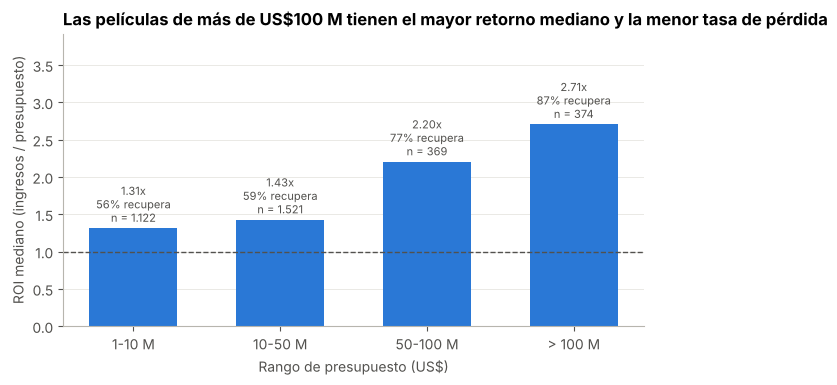

In [21]:
# G10. ROI mediano por rango de presupuesto
orden_r = ['1-10 M', '10-50 M', '50-100 M', '> 100 M']
rr = (cat.dropna(subset=['roi']).groupby('rango_presupuesto')
         .agg(roi_med=('roi', 'median'), n=('roi', 'size'), recupera=('roi', lambda s: (s >= 1).mean() * 100))
         .reindex(orden_r))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar(rr.index, rr['roi_med'], color=COL['Película'], width=0.6)
for bar_, (_, row) in zip(bars, rr.iterrows()):
    ax.text(bar_.get_x() + bar_.get_width() / 2, bar_.get_height() + 0.05,
            f"{row.roi_med:.2f}x\n{row.recupera:.0f}% recupera\nn = {row.n:,.0f}".replace(',', '.'),
            ha='center', va='bottom', fontsize=8, color=TINTA2)
ax.axhline(1, color=TINTA2, linestyle='--', linewidth=1)
ax.set_ylim(0, rr['roi_med'].max() * 1.45)
ax.set_xlabel('Rango de presupuesto (US$)'); ax.set_ylabel('ROI mediano (ingresos / presupuesto)')
ax.set_title('Las películas de más de US$100 M tienen el mayor retorno mediano y la menor tasa de pérdida')
ax.grid(axis='x', visible=False)
guardar(fig, 'ep2_10_roi_por_presupuesto.png'); plt.show()
print(rr.round(2).to_string())

                  titulo  anio_estreno  genero_principal  presupuesto_usd  ingresos_usd     roi
Dragon Ball Super: Broly          2018 Acción y Aventura        1000000.0   125002821.0 125.003
        The Devil Inside          2012            Terror        1000000.0   101800000.0 101.800
        Lost in Thailand          2012           Comedia        2200000.0   208000000.0  94.545
               Searching          2018             Drama        1000000.0    75462037.0  75.462
               Insidious          2011            Terror        1500000.0   100106454.0  66.738
              Unfriended          2014            Terror        1000000.0    62900000.0  62.900
   Paranormal Activity 2          2010            Terror        3000000.0   177512032.0  59.171
                 Get Out          2017          Misterio        4500000.0   255407969.0  56.757
                  Tunnel          2016          Suspenso        1000000.0    52444295.0  52.444
         The Last Kumite          2024 A

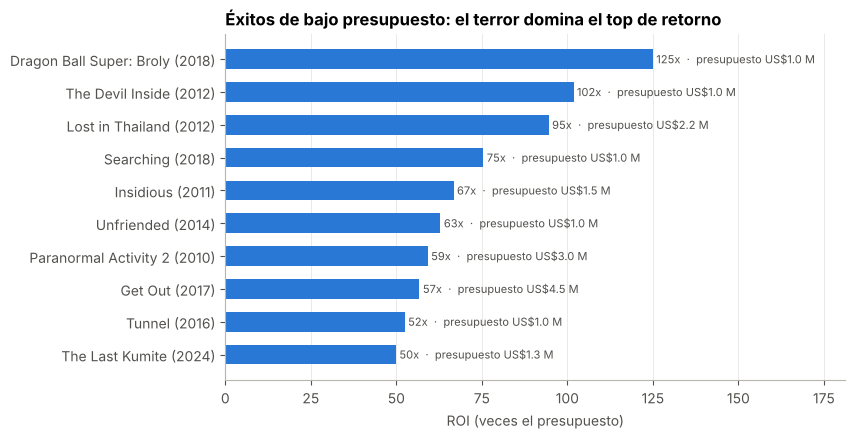

In [22]:
# G11. Top 10 películas por ROI (presupuesto ≥ US$1 M)
top_roi = cat.dropna(subset=['roi']).nlargest(10, 'roi')[['titulo', 'anio_estreno', 'genero_principal', 'presupuesto_usd', 'ingresos_usd', 'roi']]
d = top_roi.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(d['titulo'] + ' (' + d['anio_estreno'].astype(str) + ')', d['roi'], color=COL['Película'], height=0.6)
for i, (v, b) in enumerate(zip(d['roi'], d['presupuesto_usd'])):
    ax.text(v + 1, i, f'{v:.0f}x  ·  presupuesto US${b/1e6:.1f} M', va='center', fontsize=8, color=TINTA2)
ax.set_xlim(0, d['roi'].max() * 1.45)
ax.set_xlabel('ROI (veces el presupuesto)')
ax.set_title('Éxitos de bajo presupuesto: el terror domina el top de retorno')
ax.grid(axis='y', visible=False)
guardar(fig, 'ep2_11_top10_roi.png'); plt.show()
print(top_roi.to_string(index=False))

In [23]:
# G12. Joyas ocultas recomendadas para promoción (mayor valoración con al menos 100 votos)
joyas = (cat[(cat['segmento'] == 'Joya oculta') & (cat['votos'] >= 100)]
           .sort_values(['valoracion_valida', 'votos'], ascending=False)
           .groupby('tipo').head(5)[['tipo', 'titulo', 'anio_estreno', 'genero_principal', 'idioma', 'valoracion_valida', 'votos', 'popularidad_percentil']])
print(joyas.to_string(index=False))

    tipo                                 titulo  anio_estreno           genero_principal  idioma  valoracion_valida  votos  popularidad_percentil
Película                               Succubus          2024                     Terror  Inglés               9.50    157                   70.4
Película           Break the Silence: The Movie          2020                     Música Coreano               9.00    183                   13.9
Película  The Three Deaths of Marisela Escobedo          2020                 Documental Español               8.90    228                   38.0
   Serie          Adventure Time: Fionna & Cake          2023                  Animación  Inglés               8.90    208                   69.0
Película BTS: Permission to Dance on Stage - LA          2022                     Música Coreano               8.90    157                   39.0
   Serie   The Boy's Word: Blood on the Asphalt          2023                      Drama    Ruso               8.89    182  

## 4. Hallazgos principales (insumo para storytelling, informe y dashboard)

**Integración y calidad**
- El catálogo integrado tiene **31.991 contenidos** (16.000 películas y 15.991 series, tras eliminar 9 series duplicadas).
- `show_id` no sirve como llave entre fuentes (397 ids repetidos): se usa `content_id` (`M-`/`S-`).
- Las **series tienen poca evidencia de valoración**: 62% tiene menos de 10 votos (mediana: 4 votos), contra 11% en películas.
  Toda comparación de valoración entre tipos se hace solo con contenidos con ≥ 10 votos y se declara.
- El volumen anual es constante (1.000 títulos por año y tipo) y `date_added` replica el año de estreno: **no hay tendencia
  de crecimiento del catálogo que mostrar**; sí hay tendencias de valoración.

**Catálogo**
- Drama (14.769 contenidos, 46% del catálogo) y Comedia son los géneros más presentes en ambos tipos.
- Las películas son mayoritariamente en inglés (60%); las series son mucho más asiáticas: chino, japonés y coreano suman 36%
  y superan al inglés (28%). EE.UU. participa en un tercio del catálogo.

**Atractivo**
- Presencia no es atractivo: Drama queda en la mediana de popularidad, mientras Acción y Aventura, Ciencia ficción y Animación
  (películas) y Telenovela, Noticias y Talk show (series) están sobre el percentil 65.
- Popularidad y valoración están débilmente relacionadas (ver ρ de Spearman en G7).
- **5.256 "joyas ocultas"** (16% del catálogo): valoración ≥ 7 con popularidad bajo el percentil 75. Son candidatas naturales
  para campañas de visibilidad (Marketing).
- Las series se valoran mejor que las películas en todos los años (7,1–7,5 vs 6,1–6,5), con la salvedad de la menor cantidad de votos.

**Finanzas (solo películas, 22% con datos)**
- Presupuesto e ingresos están asociados, pero 37% de las películas con ROI calculable no recupera su inversión.
- El ROI mediano crece con el presupuesto (1,3x en 1–10 M → 2,7x sobre 100 M), aunque los mayores retornos individuales son
  de bajo presupuesto, sobre todo terror (Insidious, Paranormal Activity 2, Get Out).
- Precaución: las grandes producciones informan sus ingresos con más frecuencia, lo que puede favorecer su ROI (sesgo de reporte).